# Autocorrelation of read depth along the genome

Read depth in neighbouring 500 bp windows is not independent: a high-depth window tends to sit next to other high-depth windows.
Before choosing a model for how depth changes along a chromosome, this notebook measures how far that correlation reaches.

Input: `<sample>.window_stats.tsv` in `$PF8/output/` (mean and SD of depth in each 500 bp window, from step 8 of `pf8_mosdepth.sh` or `run_samples.sh`).

Run the cells one at a time, top to bottom (`conda activate krsim`, then `jupyter lab`).

## Step 1: paths and settings

In [1]:
import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Folder for the Pf8 data (change this on another laptop)
PF8 = "/Users/jbansal/Desktop/IMPERIAL/pf8"

WINDOW = 500      # bp per window, as made by pf8_profiles
MAX_LAG = 200     # largest lag in windows for the autocorrelation (200 windows = 100 kb)
PSEUDO = 0.05     # added before taking the log, so windows with zero depth do not give -inf

## Step 2: which samples have window stats

In [2]:
files = sorted(glob.glob(f"{PF8}/output/*.window_stats.tsv"))
samples = [os.path.basename(f).replace(".window_stats.tsv", "") for f in files]

info = pd.read_csv(f"{PF8}/input/Pf8_samples.txt", sep="\t", index_col="Sample")
info.loc[samples, ["Country", "Year", "Population", "% callable", "Sample type"]]

,Country,Year,Population,% callable,Sample type
Sample,,,,,
PF1066-Cx,Ghana,2014.0,AF-W,87.10,sWGA
QC0392-CW,Myanmar,2012.0,AS-SE-W,85.10,sWGA
QG0326-CW,Democratic Republic of the Congo,2014.0,AF-C,90.29,sWGA
RCN08168,Bangladesh,2016.0,AS-S-FE,85.90,sWGA
RCN14139,India,2017.0,AS-S-E,75.67,sWGA
RCN14613,Vietnam,2018.0,AS-SE-E,90.20,sWGA
SPT16706,Benin,2016.0,AF-W,88.99,sWGA
SPT18553,Mali,2016.0,AF-W,84.88,sWGA
SPT24161,Cameroon,2017.0,AF-W,87.34,sWGA


## Step 3: read every sample into one table (14 nuclear chromosomes only)

In [3]:
tables = []
for sample, f in zip(samples, files):
    df = pd.read_csv(f, sep="\t")
    df.insert(0, "sample", sample)
    tables.append(df)
depth = pd.concat(tables, ignore_index=True)

depth = depth[~depth["chrom"].str.contains("API|MIT")]   # drop the apicoplast and mitochondrion
depth

,sample,chrom,start,end,mean,sd
0,PF1066-Cx,Pf3D7_01_v3,0,500,0.00,0.00
1,PF1066-Cx,Pf3D7_01_v3,500,1000,0.19,0.40
2,PF1066-Cx,Pf3D7_01_v3,1000,1500,0.20,0.40
3,PF1066-Cx,Pf3D7_01_v3,1500,2000,0.00,0.00
4,PF1066-Cx,Pf3D7_01_v3,2000,2500,0.19,0.39
...,...,...,...,...,...,...
606650,SPT83245,Pf3D7_14_v3,3289500,3290000,117.99,22.93
606651,SPT83245,Pf3D7_14_v3,3290000,3290500,28.52,27.08
606652,SPT83245,Pf3D7_14_v3,3290500,3291000,2.43,3.63
606653,SPT83245,Pf3D7_14_v3,3291000,3291500,0.00,0.00


In [4]:
# windows per chromosome (the same for every sample)
depth[depth["sample"] == samples[0]].groupby("chrom").size()

chrom
Pf3D7_01_v3    1282
Pf3D7_02_v3    1895
Pf3D7_03_v3    2136
Pf3D7_04_v3    2401
Pf3D7_05_v3    2688
Pf3D7_06_v3    2837
Pf3D7_07_v3    2891
Pf3D7_08_v3    2946
Pf3D7_09_v3    3084
Pf3D7_10_v3    3376
Pf3D7_11_v3    4077
Pf3D7_12_v3    4543
Pf3D7_13_v3    5851
Pf3D7_14_v3    6584
dtype: int64

## Step 4: put the samples on the same scale

Samples were sequenced to very different depths, so each sample's window means are divided by that sample's median window mean (`rel` = 1 means a typical window).
Then `log_rel = log(rel + PSEUDO)`, because depth varies by multiples rather than by fixed amounts.

In [5]:
median = depth.groupby("sample")["mean"].median()
depth["rel"] = depth["mean"] / depth["sample"].map(median)
depth["log_rel"] = np.log(depth["rel"] + PSEUDO)

summary = pd.DataFrame({
    "median depth": median,
    "zero windows": depth.groupby("sample")["mean"].apply(lambda m: (m == 0).sum()),
})
summary

,median depth,zero windows
sample,,
PF1066-Cx,40.51,474
QC0392-CW,47.13,816
QG0326-CW,75.25,16
RCN08168,126.83,40
RCN14139,25.49,1813
RCN14613,105.41,58
SPT16706,96.57,90
SPT18553,41.75,1493
SPT24161,59.86,314


## Step 5: look at one sample along one chromosome

In [12]:
print(depth)

           sample        chrom    start      end    mean     sd       rel  \
0       PF1066-Cx  Pf3D7_01_v3        0      500    0.00   0.00  0.000000   
1       PF1066-Cx  Pf3D7_01_v3      500     1000    0.19   0.40  0.004690   
2       PF1066-Cx  Pf3D7_01_v3     1000     1500    0.20   0.40  0.004937   
3       PF1066-Cx  Pf3D7_01_v3     1500     2000    0.00   0.00  0.000000   
4       PF1066-Cx  Pf3D7_01_v3     2000     2500    0.19   0.39  0.004690   
...           ...          ...      ...      ...     ...    ...       ...   
606650   SPT83245  Pf3D7_14_v3  3289500  3290000  117.99  22.93  3.135530   
606651   SPT83245  Pf3D7_14_v3  3290000  3290500   28.52  27.08  0.757906   
606652   SPT83245  Pf3D7_14_v3  3290500  3291000    2.43   3.63  0.064576   
606653   SPT83245  Pf3D7_14_v3  3291000  3291500    0.00   0.00  0.000000   
606654   SPT83245  Pf3D7_14_v3  3291500  3291936    0.00   0.00  0.000000   

         log_rel  
0      -2.995732  
1      -2.906071  
2      -2.901567  

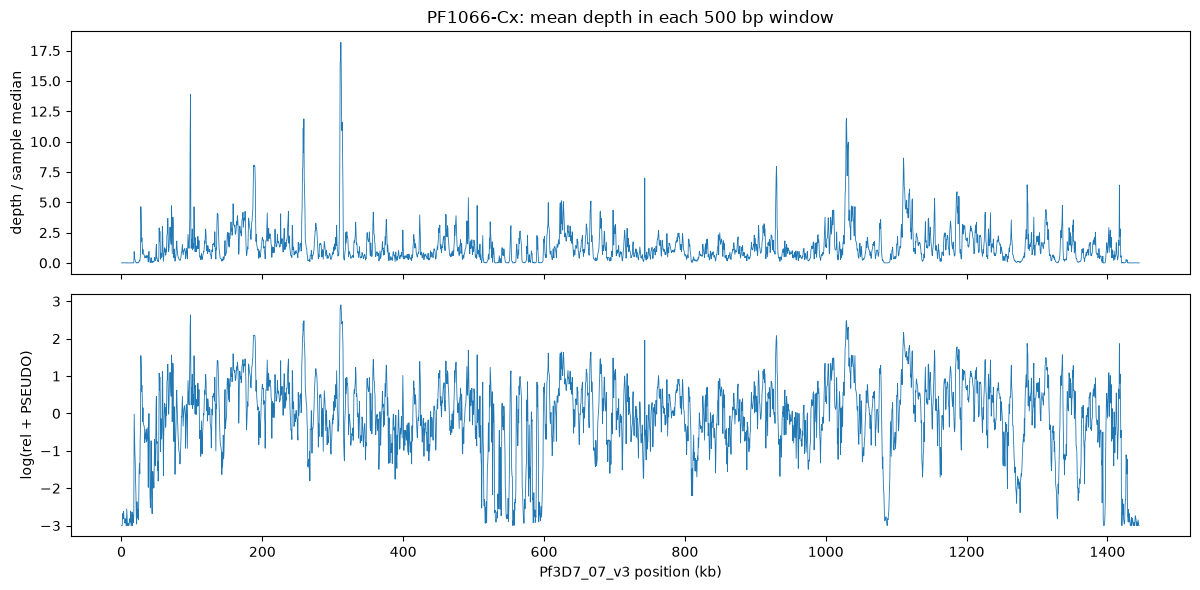

In [6]:
SAMPLE = samples[0]
CHROM = "Pf3D7_07_v3"

one = depth[(depth["sample"] == SAMPLE) & (depth["chrom"] == CHROM)]

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(one["start"] / 1e3, one["rel"], lw=0.6)
axes[0].set_ylabel("depth / sample median")
axes[1].plot(one["start"] / 1e3, one["log_rel"], lw=0.6)
axes[1].set_ylabel("log(rel + PSEUDO)")
axes[1].set_xlabel(f"{CHROM} position (kb)")
axes[0].set_title(f"{SAMPLE}: mean depth in each {WINDOW} bp window")
fig.tight_layout()

## Step 6: autocorrelation function

For a series `x` along one chromosome, the autocorrelation at lag `k` is the correlation between each window and the window `k` windows further along.
It is computed separately for each chromosome, so the jump from the end of one chromosome to the start of the next is never counted.

In [7]:
def acf(x, max_lag):
    """Autocorrelation of x at lags 0..max_lag."""
    x = np.asarray(x, dtype=float)
    x = x - x.mean()
    var = (x ** 2).sum()
    return np.array([(x[:len(x) - k] * x[k:]).sum() / var for k in range(max_lag + 1)])

## Step 7: ACF of one sample, one line per chromosome

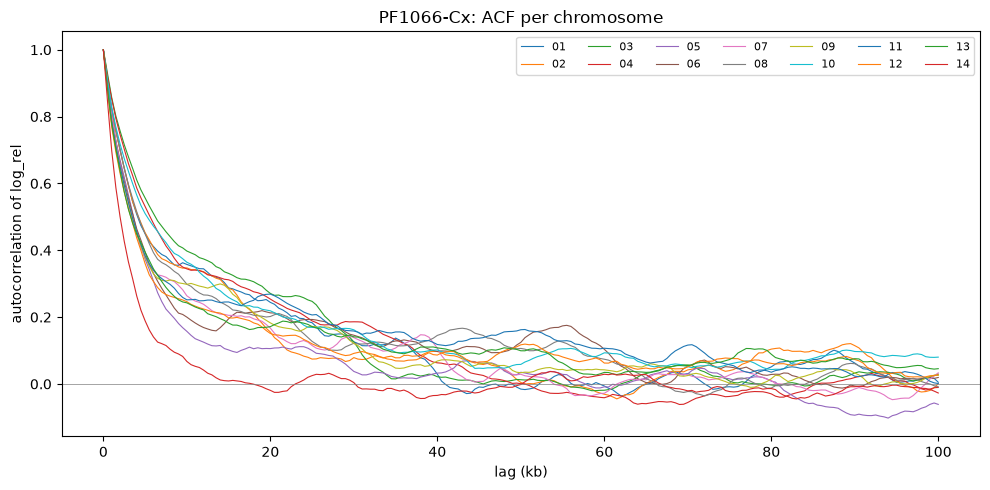

In [8]:
lags_kb = np.arange(MAX_LAG + 1) * WINDOW / 1e3

fig, ax = plt.subplots(figsize=(10, 5))
for chrom, g in depth[depth["sample"] == SAMPLE].groupby("chrom"):
    ax.plot(lags_kb, acf(g["log_rel"], MAX_LAG), lw=0.8, label=chrom.replace("Pf3D7_", "").replace("_v3", ""))
ax.axhline(0, color="grey", lw=0.5)
ax.set_xlabel("lag (kb)")
ax.set_ylabel("autocorrelation of log_rel")
ax.set_title(f"{SAMPLE}: ACF per chromosome")
ax.legend(ncol=7, fontsize=8)
fig.tight_layout()

## Step 8: ACF of every sample (averaged over the 14 chromosomes)

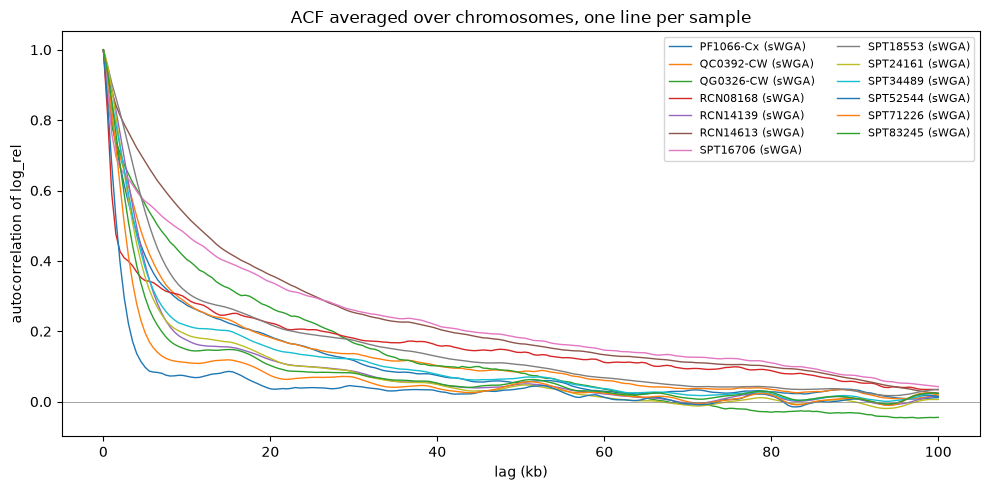

In [9]:
acfs = {}
for sample in samples:
    per_chrom = [acf(g["log_rel"], MAX_LAG) for _, g in depth[depth["sample"] == sample].groupby("chrom")]
    acfs[sample] = np.mean(per_chrom, axis=0)
acfs = pd.DataFrame(acfs, index=pd.Index(lags_kb, name="lag (kb)"))

fig, ax = plt.subplots(figsize=(10, 5))
for sample in samples:
    ax.plot(lags_kb, acfs[sample], lw=1, label=f"{sample} ({info.loc[sample, 'Sample type']})")
ax.axhline(0, color="grey", lw=0.5)
ax.set_xlabel("lag (kb)")
ax.set_ylabel("autocorrelation of log_rel")
ax.set_title("ACF averaged over chromosomes, one line per sample")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()

In [10]:
# the ACF at a few lags, as numbers
acfs.loc[[0.5, 1, 2, 5, 10, 25, 50, 100]].T.round(2)

lag (kb),0.5,1.0,2.0,5.0,10.0,25.0,50.0,100.0
PF1066-Cx,0.89,0.80,0.67,0.41,0.27,0.15,0.05,0.01
QC0392-CW,0.89,0.79,0.70,0.45,0.28,0.15,0.09,0.02
QG0326-CW,0.86,0.78,0.71,0.56,0.40,0.23,0.08,-0.04
RCN08168,0.82,0.59,0.43,0.34,0.29,0.20,0.14,0.03
RCN14139,0.95,0.89,0.76,0.39,0.17,0.10,0.05,0.02
RCN14613,0.94,0.88,0.81,0.68,0.53,0.30,0.16,0.02
SPT16706,0.89,0.76,0.66,0.57,0.47,0.30,0.18,0.04
SPT18553,0.96,0.91,0.82,0.54,0.31,0.19,0.10,0.04
SPT24161,0.96,0.89,0.73,0.35,0.19,0.10,0.05,0.01
SPT34489,0.93,0.85,0.72,0.38,0.22,0.13,0.07,0.02


## Step 9: same plot with a log y-axis

If the ACF falls as a straight line here, it decays exponentially, which is what an AR(1) process gives (ACF at lag k = φ^k).
A curve that bends upward instead means the correlation reaches further than AR(1) allows.

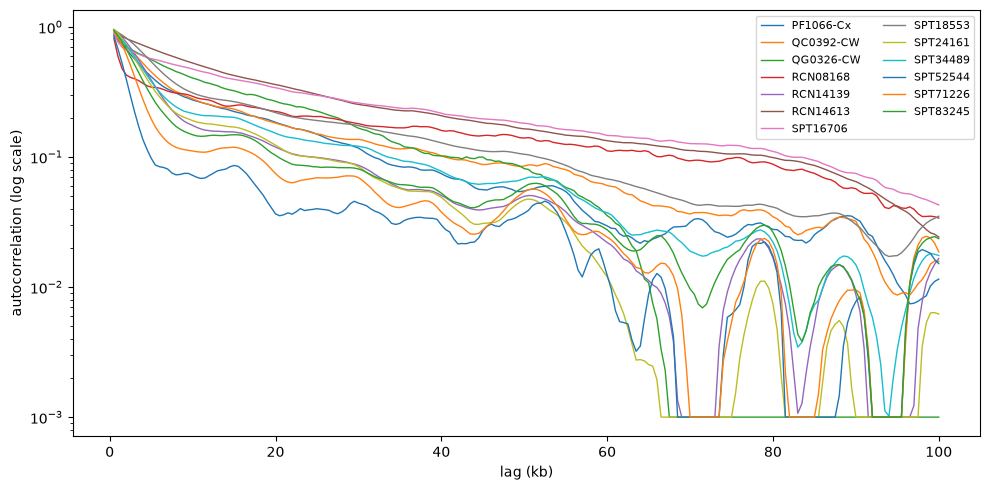

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
for sample in samples:
    ax.plot(lags_kb[1:], acfs[sample].iloc[1:].clip(lower=1e-3), lw=1, label=sample)
ax.set_yscale("log")
ax.set_xlabel("lag (kb)")
ax.set_ylabel("autocorrelation (log scale)")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()